/home/as5606/miniconda3/envs/biomedclip/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading BioMedCLIP...

X-ray: 385 UPD records


X-ray: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 385/385 [00:18<00:00, 20.29it/s]



MRI: 1241 UPD records


MRI: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1241/1241 [00:57<00:00, 21.64it/s]


...

Histology: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1229/1229 [00:58<00:00, 21.08it/s]



Pathology: 140 UPD records


Pathology: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 140/140 [00:06<00:00, 22.64it/s]



Total signals: (4596, 512)
Saved embeddings.

Running UMAP...


ModuleNotFoundError: No module named 'umap'

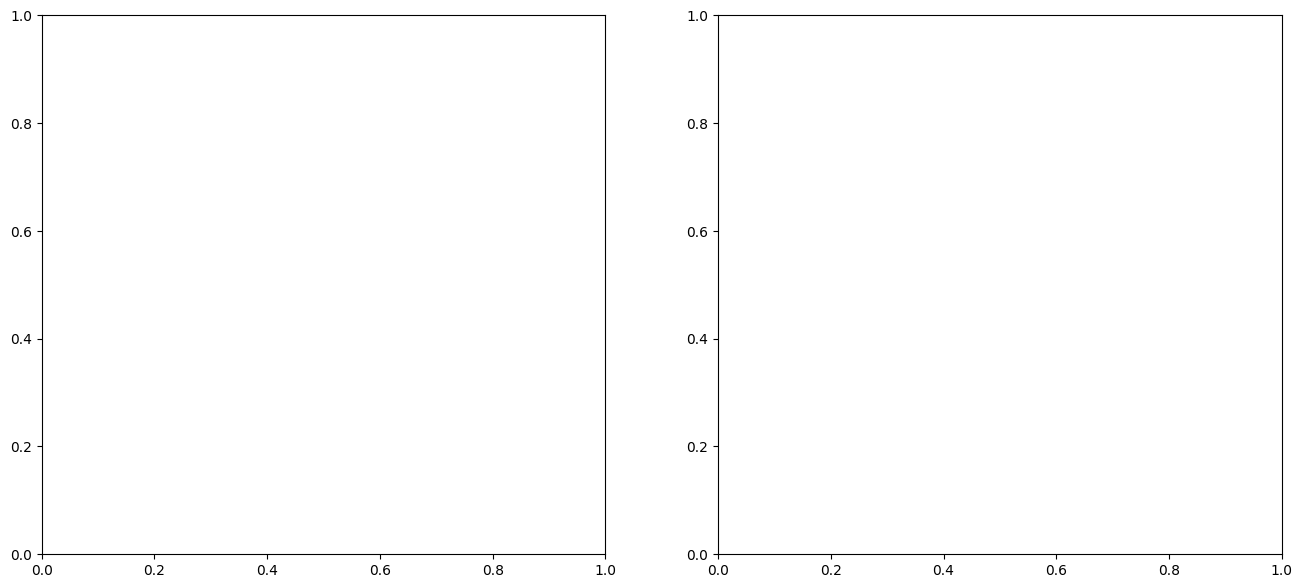

In [1]:
import os
os.chdir("/home/as5606/projects/CLIP-UP")
import sys
sys.path.insert(0, "/home/as5606/projects/CLIP-UP")

import json
import numpy as np
import torch
from PIL import Image
from tqdm import tqdm
from open_clip import create_model_from_pretrained, get_tokenizer

# ── Config ────────────────────────────────────────────────────────────────────
DOMAINS = {
    "X-ray":      "/home/as5606/projects/Super_LlaVA_Med/dataset_3/x_ray/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "MRI":        "/home/as5606/projects/Super_LlaVA_Med/dataset_3/MRI/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "CT":         "/home/as5606/projects/Super_LlaVA_Med/dataset_3/CT/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "Histology":  "/home/as5606/projects/Super_LlaVA_Med/dataset_3/histology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "Pathology":  "/home/as5606/projects/Super_LlaVA_Med/dataset_3/gross_pathology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
}
OUT_DIR = "/home/as5606/projects/Super_LlaVA_Med/paper_graphs"
device  = "cuda"

# ── Load BioMedCLIP ───────────────────────────────────────────────────────────
print("Loading BioMedCLIP...")
model, preprocess = create_model_from_pretrained(
    'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224', device=device
)
tokenizer = get_tokenizer('hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224')
model.eval()
model.requires_grad_(False)

# ── Extract CLIP signals ──────────────────────────────────────────────────────
all_signals, all_labels = [], []

for domain_name, val_path in DOMAINS.items():
    records = [json.loads(l) for l in open(val_path) if json.loads(l)["type"] == "upd"]
    print(f"\n{domain_name}: {len(records)} UPD records")

    for rec in tqdm(records, desc=domain_name):
        try:
            image = Image.open(rec["image_path"]).convert("RGB")
            img_tensor  = preprocess(image).unsqueeze(0).to(device)
            text_tokens = tokenizer([rec["statement"]]).to(device)

            with torch.inference_mode():
                img_feat  = model.encode_image(img_tensor)
                img_feat  = img_feat / img_feat.norm(dim=-1, keepdim=True)
                txt_feat  = model.encode_text(text_tokens)
                txt_feat  = txt_feat / txt_feat.norm(dim=-1, keepdim=True)
                signal    = (img_feat * txt_feat).squeeze(0).cpu().float().numpy()

            all_signals.append(signal)
            all_labels.append(domain_name)
        except Exception as e:
            pass

all_signals = np.array(all_signals)
all_labels  = np.array(all_labels)
print(f"\nTotal signals: {all_signals.shape}")

# ── Save embeddings ───────────────────────────────────────────────────────────
np.save(os.path.join(OUT_DIR, "clip_signals.npy"), all_signals)
np.save(os.path.join(OUT_DIR, "clip_labels.npy"),  all_labels)
print("Saved embeddings.")

# ── UMAP + t-SNE ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

COLORS = {
    "X-ray":     "#e41a1c",
    "MRI":       "#377eb8",
    "CT":        "#4daf4a",
    "Histology": "#ff7f00",
    "Pathology": "#984ea3",
}

def plot_2d(coords, labels, title, ax):
    for domain in DOMAINS.keys():
        mask = labels == domain
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   c=COLORS[domain], s=4, alpha=0.5, label=domain)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# UMAP
print("\nRunning UMAP...")
import umap
reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=30, min_dist=0.1)
umap_coords = reducer.fit_transform(all_signals)
plot_2d(umap_coords, all_labels, "UMAP — BioMedCLIP CLIP Signal (UPD)", axes[0])

# t-SNE
print("Running t-SNE...")
from sklearn.manifold import TSNE
tsne_coords = TSNE(n_components=2, random_state=42, perplexity=40, n_iter=1000).fit_transform(all_signals)
plot_2d(tsne_coords, all_labels, "t-SNE — BioMedCLIP CLIP Signal (UPD)", axes[1])

handles = [mpatches.Patch(color=COLORS[d], label=d) for d in DOMAINS.keys()]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=11, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1])

out_path = os.path.join(OUT_DIR, "clip_signal_upd_visualization.png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"\nSaved → {out_path}")
plt.show()


In [3]:
!pip install umap-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 43.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 65.5 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [umap-learn] 3/4 [umap-learn]]



Running UMAP...


/home/as5606/miniconda3/envs/biomedclip/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running t-SNE...

Saved → /home/as5606/projects/Super_LlaVA_Med/paper_graphs/clip_signal_upd_visualization.png


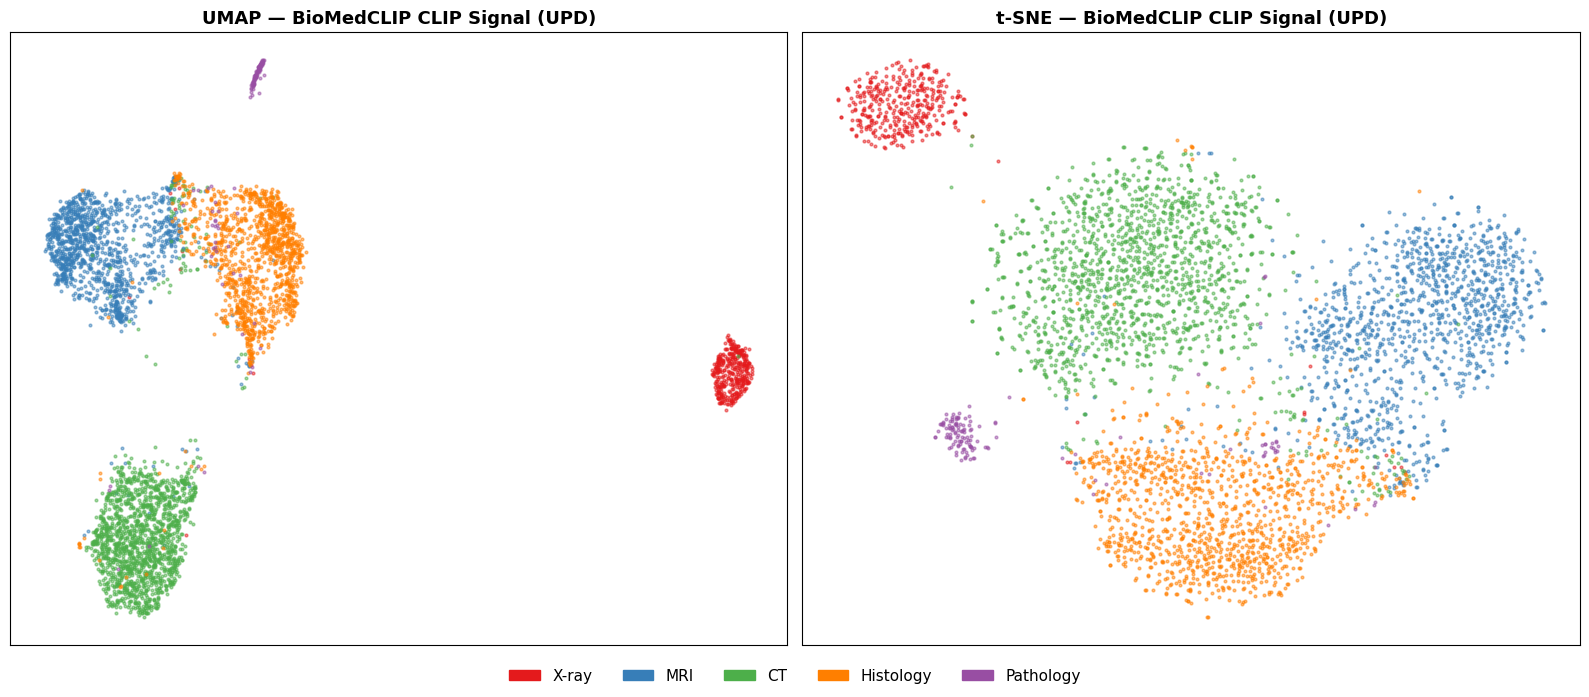

In [5]:
import numpy as np

all_signals = np.load("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/clip_signals.npy")
all_labels  = np.load("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/clip_labels.npy")


# ── UMAP + t-SNE ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

COLORS = {
    "X-ray":     "#e41a1c",
    "MRI":       "#377eb8",
    "CT":        "#4daf4a",
    "Histology": "#ff7f00",
    "Pathology": "#984ea3",
}

def plot_2d(coords, labels, title, ax):
    for domain in DOMAINS.keys():
        mask = labels == domain
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   c=COLORS[domain], s=4, alpha=0.5, label=domain)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# UMAP
print("\nRunning UMAP...")
import umap
reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=30, min_dist=0.1)
umap_coords = reducer.fit_transform(all_signals)
plot_2d(umap_coords, all_labels, "UMAP — BioMedCLIP CLIP Signal (UPD)", axes[0])

# t-SNE
print("Running t-SNE...")
from sklearn.manifold import TSNE
tsne_coords = TSNE(n_components=2, random_state=42, perplexity=40, max_iter=1000).fit_transform(all_signals)
plot_2d(tsne_coords, all_labels, "t-SNE — BioMedCLIP CLIP Signal (UPD)", axes[1])

handles = [mpatches.Patch(color=COLORS[d], label=d) for d in DOMAINS.keys()]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=11, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1])

out_path = os.path.join(OUT_DIR, "clip_signal_upd_visualization.png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"\nSaved → {out_path}")
plt.show()


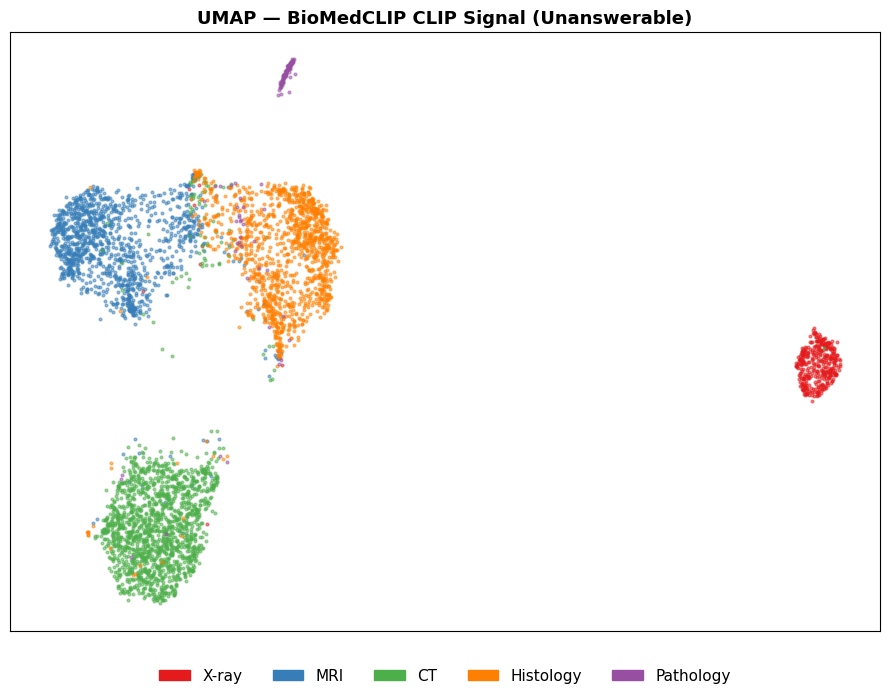

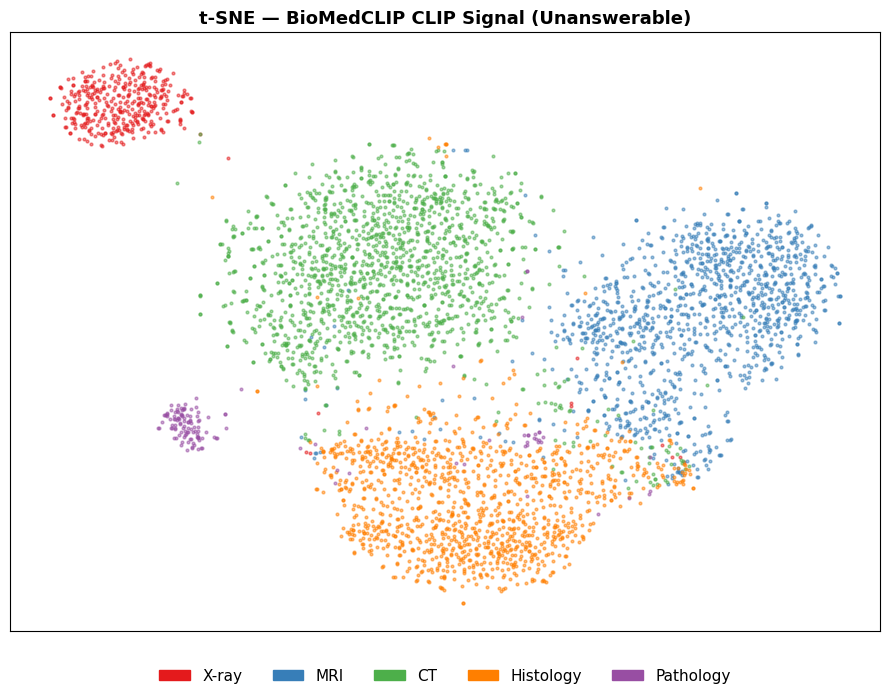

In [6]:
# Save UMAP only
fig_umap, ax_umap = plt.subplots(figsize=(9, 7))
plot_2d(umap_coords, all_labels, "UMAP — BioMedCLIP CLIP Signal (Unanswerable)", ax_umap)
handles = [mpatches.Patch(color=COLORS[d], label=d) for d in DOMAINS.keys()]
fig_umap.legend(handles=handles, loc="lower center", ncol=5, fontsize=11, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1])
fig_umap.savefig("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/umap_upd.pdf", dpi=150, bbox_inches="tight")
plt.show()

# Save t-SNE only
fig_tsne, ax_tsne = plt.subplots(figsize=(9, 7))
plot_2d(tsne_coords, all_labels, "t-SNE — BioMedCLIP CLIP Signal (Unanswerable)", ax_tsne)
fig_tsne.legend(handles=handles, loc="lower center", ncol=5, fontsize=11, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1])
fig_tsne.savefig("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/tsne_upd.pdf", dpi=150, bbox_inches="tight")
plt.show()


In [7]:
import json
import numpy as np
import torch
from PIL import Image
from tqdm import tqdm
from open_clip import create_model_from_pretrained, get_tokenizer

DOMAINS = {
    "X-ray":      "/home/as5606/projects/Super_LlaVA_Med/dataset_3/x_ray/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "MRI":        "/home/as5606/projects/Super_LlaVA_Med/dataset_3/MRI/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "CT":         "/home/as5606/projects/Super_LlaVA_Med/dataset_3/CT/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "Histology":  "/home/as5606/projects/Super_LlaVA_Med/dataset_3/histology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "Pathology":  "/home/as5606/projects/Super_LlaVA_Med/dataset_3/gross_pathology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
}
OUT_DIR = "/home/as5606/projects/Super_LlaVA_Med/paper_graphs"
device  = "cuda"

all_signals, all_labels = [], []

for domain_name, val_path in DOMAINS.items():
    records = [json.loads(l) for l in open(val_path) if json.loads(l)["type"] == "standard"]
    print(f"\n{domain_name}: {len(records)} standard records")

    for rec in tqdm(records, desc=domain_name):
        try:
            image = Image.open(rec["image_path"]).convert("RGB")
            img_tensor  = preprocess(image).unsqueeze(0).to(device)
            text_tokens = tokenizer([rec["statement"]]).to(device)

            with torch.inference_mode():
                img_feat = model.encode_image(img_tensor)
                img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
                txt_feat = model.encode_text(text_tokens)
                txt_feat = txt_feat / txt_feat.norm(dim=-1, keepdim=True)
                signal   = (img_feat * txt_feat).squeeze(0).cpu().float().numpy()

            all_signals.append(signal)
            all_labels.append(domain_name)
        except:
            pass

all_signals = np.array(all_signals)
all_labels  = np.array(all_labels)
print(f"\nTotal: {all_signals.shape}")

np.save(f"{OUT_DIR}/clip_signals_standard.npy", all_signals)
np.save(f"{OUT_DIR}/clip_labels_standard.npy",  all_labels)
print("Saved.")



X-ray: 385 standard records


X-ray: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 385/385 [00:12<00:00, 30.68it/s]



MRI: 1241 standard records


MRI: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1241/1241 [00:40<00:00, 30.45it/s]



CT: 1601 standard records


...


Histology: 1229 standard records


Histology: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1229/1229 [00:40<00:00, 30.43it/s]



Pathology: 140 standard records


Pathology: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 140/140 [00:04<00:00, 31.09it/s]


Total: (4596, 512)
Saved.


Running UMAP...


/home/as5606/miniconda3/envs/biomedclip/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running t-SNE...


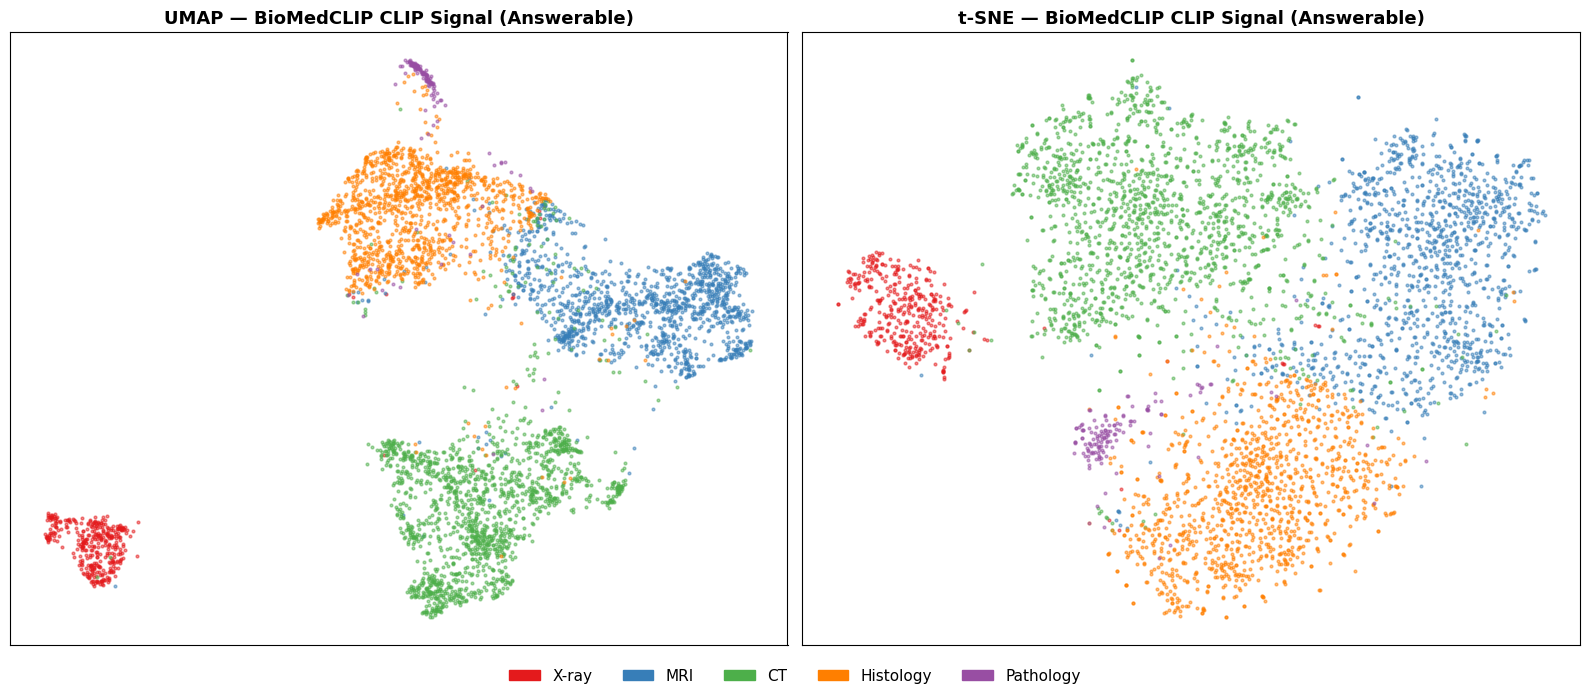

In [8]:
import umap
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

COLORS = {
    "X-ray":     "#e41a1c",
    "MRI":       "#377eb8",
    "CT":        "#4daf4a",
    "Histology": "#ff7f00",
    "Pathology": "#984ea3",
}

def plot_2d(coords, labels, title, ax):
    for domain in DOMAINS.keys():
        mask = labels == domain
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   c=COLORS[domain], s=4, alpha=0.5, label=domain)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

all_signals = np.load(f"{OUT_DIR}/clip_signals_standard.npy")
all_labels  = np.load(f"{OUT_DIR}/clip_labels_standard.npy")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

print("Running UMAP...")
umap_coords = umap.UMAP(n_components=2, random_state=42, n_neighbors=30, min_dist=0.1).fit_transform(all_signals)
plot_2d(umap_coords, all_labels, "UMAP — BioMedCLIP CLIP Signal (Answerable)", axes[0])

print("Running t-SNE...")
tsne_coords = TSNE(n_components=2, random_state=42, perplexity=40, max_iter=1000).fit_transform(all_signals)
plot_2d(tsne_coords, all_labels, "t-SNE — BioMedCLIP CLIP Signal (Answerable)", axes[1])

handles = [mpatches.Patch(color=COLORS[d], label=d) for d in DOMAINS.keys()]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=11, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(f"{OUT_DIR}/clip_signal_standard_visualization.pdf", bbox_inches="tight")
plt.show()


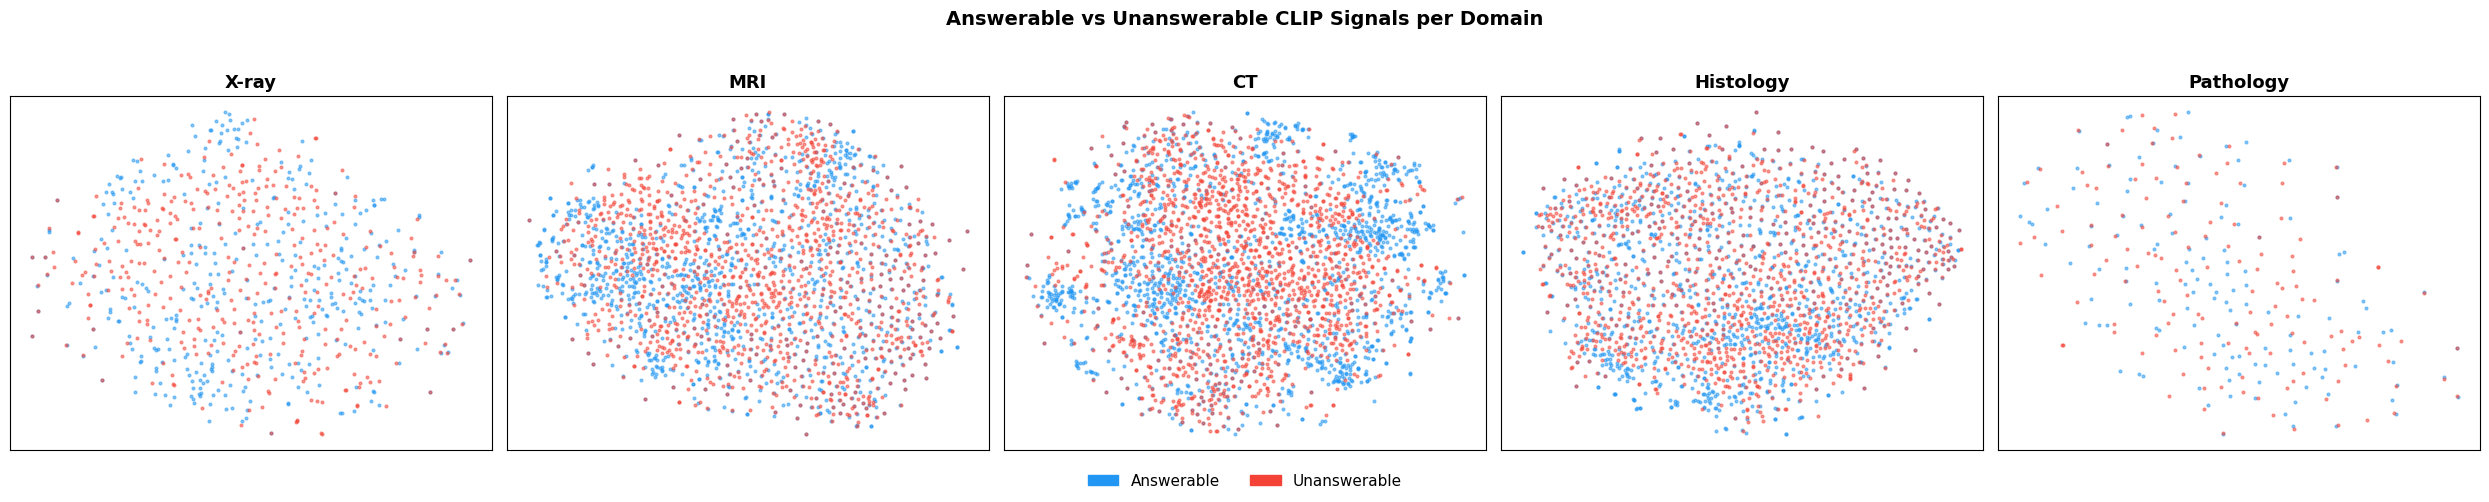

In [9]:
upd_signals  = np.load(f"{OUT_DIR}/clip_signals.npy")
upd_labels   = np.load(f"{OUT_DIR}/clip_labels.npy")
std_signals  = np.load(f"{OUT_DIR}/clip_signals_standard.npy")
std_labels   = np.load(f"{OUT_DIR}/clip_labels_standard.npy")

domain_list = ["X-ray", "MRI", "CT", "Histology", "Pathology"]

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, domain in zip(axes, domain_list):
    # Get signals for this domain only
    std_mask = std_labels == domain
    upd_mask = upd_labels == domain

    signals = np.concatenate([std_signals[std_mask], upd_signals[upd_mask]])
    labels  = ["Answerable"] * std_mask.sum() + ["Unanswerable"] * upd_mask.sum()
    labels  = np.array(labels)

    coords = TSNE(n_components=2, random_state=42, perplexity=40, max_iter=1000).fit_transform(signals)

    for typ, color in [("Answerable", "#2196F3"), ("Unanswerable", "#F44336")]:
        mask = labels == typ
        ax.scatter(coords[mask, 0], coords[mask, 1], c=color, s=4, alpha=0.5, label=typ)

    ax.set_title(domain, fontsize=13, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])

handles = [mpatches.Patch(color="#2196F3", label="Answerable"),
           mpatches.Patch(color="#F44336", label="Unanswerable")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=11, frameon=False)
plt.suptitle("Answerable vs Unanswerable CLIP Signals per Domain", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.savefig(f"{OUT_DIR}/answerable_vs_unanswerable_tsne.pdf", bbox_inches="tight")
plt.show()


In [ ]:
std_signals = np.load(f"{OUT_DIR}/clip_signals_standard.npy")
std_labels  = np.load(f"{OUT_DIR}/clip_labels_standard.npy")

print("Running t-SNE for answerable...")
tsne_std_coords = TSNE(n_components=2, random_state=42, perplexity=40, max_iter=1000).fit_transform(std_signals)

fig, ax = plt.subplots(figsize=(9, 7))
plot_2d(tsne_std_coords, std_labels, "t-SNE — BioMedCLIP CLIP Signal (Answerable)", ax)
handles = [mpatches.Patch(color=COLORS[d], label=d) for d in DOMAINS.keys()]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=11, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(f"{OUT_DIR}/tsne_standard.pdf", bbox_inches="tight")
plt.show()
